# Comparison: `ppc_gwtc5_k10`, `ppc_gwtc5_k100_gauss`

Each run uses its own chain as it is on disk (re-run the notebook to pick up chains that have grown). Masses are
windowed ($m_2 > 3\,M_\odot$) before any marginal is taken; spin quantities are the windowed population marginal and
the conditional's per-$(m_1, q)$ moments, read from the chain or rebuilt from the spin field (`notebooks/analysis.py`,
printed per run). Bands are 90% over draws; lines are medians. The runs are independent chains, so differences are
read from whether the bands overlap, not from draw-by-draw differences.

In [1]:
import os
os.environ.setdefault('JAX_PLATFORMS', 'cpu')
os.environ.setdefault('XLA_FLAGS', '--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1')
for v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(v, '1')
import sys
REPO = '/mnt/home/jheinzel/bbh-pixelpop-constraints'
sys.path.insert(0, REPO); sys.path.insert(0, os.path.join(REPO, 'notebooks'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pixelpop                     # switches matplotlib to Agg on import, so before %matplotlib inline
%matplotlib inline
import plot_style
plot_style.apply()
import analysis as A
from analysis import band, fmt
from model import SPIN_REF_MASSES

RUNS = ['ppc_gwtc5_k10', 'ppc_gwtc5_k100_gauss']
NAME = 'gwtc5_field_vs_gauss_k100'
R = {}
for run in RUNS:
    r = A.load_run(run)
    R[run] = r
    print(f'{run}: {r.spin_model} model, k = {r.k}, {r.n_chains} chain(s) x {r.n_draws} draws; spins {r.spin_source}'
          + (f' (rebuild vs saved marginal, max total variation {r.rebuild_tv:.1e})' if r.rebuild_tv is not None else ''))
COL = {run: f'C{i}' for i, run in enumerate(RUNS)}
LS = {run: '-' if i == 0 else '--' for i, run in enumerate(RUNS)}
LAB = {run: run.replace('ppc_', '').replace('_', r'\_') for run in RUNS}

/mnt/home/jheinzel/venvs/gwjax313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ERROR:2026-10-22 14:10:43,173:jax._src.xla_bridge:491: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/mnt/home/jheinzel/venvs/gwjax313/lib/python3.13/site-packages/jax/_src/xla_bridge.py", line 489, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/mnt/home/jheinzel/venvs/gwjax313/lib/python3.13/site-packages/jax_plugins/xla_cuda13/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/mnt/home/jheinzel/venvs/gwjax313/lib/python3.13/site-packages/jax_plugins/xla_cuda13/__init__.py", line 285, in _check_cuda_versions
    local_device_count = cuda_versions.cuda_device_count()
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE


/mnt/home/jheinzel/venvs/gwjax313/lib/python3.13/site-packages/htcondor/__init__.py:49: UserWarning: Neither the environment variable CONDOR_CONFIG, /etc/condor/, /usr/local/etc/, nor ~condor/ contain a condor_config source. Therefore, we are using a null condor_config.
  _warnings.warn(message)


ppc_gwtc5_k10: field model, k = 10, 2 chain(s) x 1000 draws; spins rebuilt from the saved spin latents on all 1000 draws per chain (results/post_processing/for_plotting/ppc_gwtc5_k10/) (rebuild vs saved marginal, max total variation 3.2e-03)


ppc_gwtc5_k100_gauss: gauss model, k = 100, 2 chain(s) x 1000 draws; spins rebuilt from the saved spin latents on all 1000 draws per chain (results/post_processing/for_plotting/ppc_gwtc5_k100_gauss/) (rebuild vs saved marginal, max total variation 1.0e-06)


## Convergence and fit

In [2]:
def cell(df, k):
    if k not in df.index:
        return ''
    r = df.loc[k]
    return f"{r['median']:.3f} [{r['lo5']:.3f}, {r['hi95']:.3f}]  (ESS {r['ess']:.0f}, R-hat {r['rhat']:.3f})"
keys = []
for run in RUNS:
    keys += [k for k in R[run].summary.index if k not in keys]
pd.set_option('display.max_colwidth', 80)
pd.DataFrame({run: [cell(R[run].summary, k) for k in keys] for run in RUNS}, index=keys)

,ppc_gwtc5_k10,ppc_gwtc5_k100_gauss
lnsigma,"1.066 [0.682, 1.496] (ESS 888, R-hat 1.001)","1.072 [0.718, 1.483] (ESS 1084, R-hat 1.000)"
log_nu_spde,"0.331 [-0.263, 1.025] (ESS 1162, R-hat 1.003)","0.281 [-0.286, 0.944] (ESS 1370, R-hat 1.002)"
log_ranges[ln m1],"2.939 [2.478, 3.502] (ESS 836, R-hat 1.002)","3.000 [2.526, 3.584] (ESS 1008, R-hat 1.001)"
log_ranges[q],"4.339 [3.797, 4.580] (ESS 1011, R-hat 0.999)","4.331 [3.804, 4.584] (ESS 1142, R-hat 1.000)"
lnsigma_spin,"1.343 [0.922, 1.854] (ESS 852, R-hat 1.002)",
log_nu_spin,"0.692 [0.038, 1.295] (ESS 1399, R-hat 1.000)",
log_ranges_spin[ln m1 mode],"4.411 [3.941, 4.589] (ESS 771, R-hat 0.999)",
log_ranges_spin[q mode],"4.465 [4.132, 4.595] (ESS 1512, R-hat 0.999)",
log_ranges_spin[chi_eff],"3.234 [2.797, 3.673] (ESS 785, R-hat 1.000)",
log_ranges_spin[chi_p],"3.916 [3.482, 4.365] (ESS 902, R-hat 1.000)",


Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_traces.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_traces.pdf'

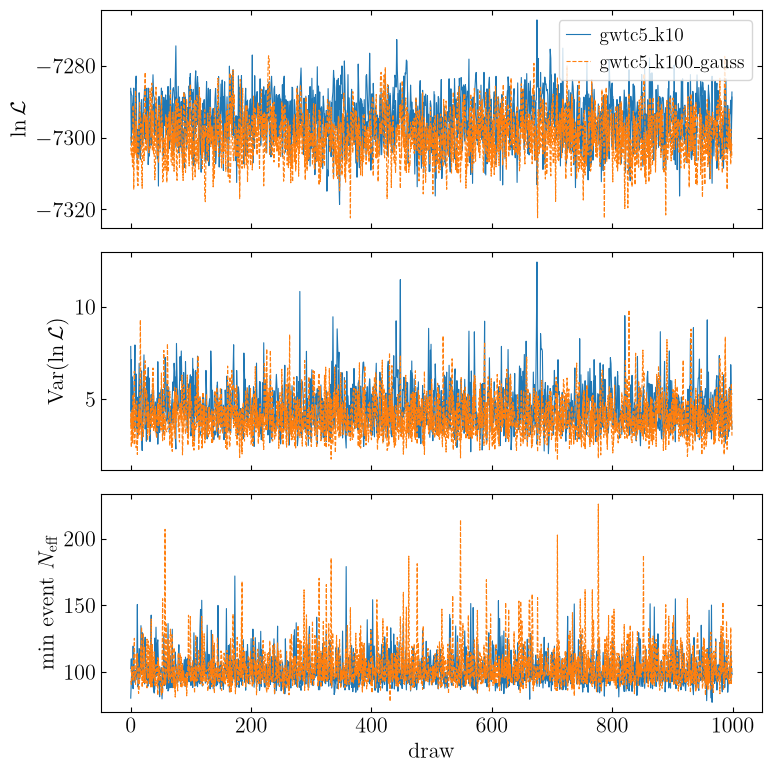

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
for run in RUNS:
    S = R[run].S
    for c in range(S['log_likelihood'].shape[0]):
        for ax, y in zip(axes, (S['log_likelihood'][c], S['log_likelihood_variance'][c], S['event_neff'][c].min(-1))):
            ax.plot(y, lw=0.8, color=COL[run], ls=LS[run], label=LAB[run] if (c == 0 and ax is axes[0]) else None)
for ax, lab in zip(axes, (r'$\ln \mathcal{L}$', r'$\mathrm{Var}(\ln \mathcal{L})$', r'min event $N_\mathrm{eff}$')):
    ax.set_ylabel(lab)
axes[0].legend(**plot_style.LEG_KW); axes[-1].set_xlabel('draw')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_traces')

In [4]:
n = 10
worst = {run: R[run].neff.sort_values('median').head(n) for run in RUNS}
pd.concat({run: w[['median', 'frac < 100']].reset_index().rename(columns={'index': 'event'}) for run, w in worst.items()},
          axis=1).round(2)

ppc_gwtc5_k10                        ppc_gwtc5_k100_gauss              \
             event      median frac < 100                event      median   
0  GW191127_050227  115.879997       0.21      GW190805_211137  123.779999   
1  GW200216_220804  122.320000       0.14      GW200216_220804  131.169998   
2  GW240526_093944  129.199997       0.16      GW191127_050227  136.070007   
3  GW190805_211137  172.149994       0.04      GW240526_093944  139.270004   
4  GW241116_151753  173.440002       0.03      GW241116_151753  175.149994   
5  GW240618_071627  183.800003       0.03      GW240107_013215  206.990005   
6  GW241114_024711  214.589996       0.01      GW240618_071627  210.690002   
7  GW240107_013215  217.839996       0.01      GW231230_170116  259.679993   
8  GW230630_125806  236.600006       0.00      GW191230_180458  260.720001   
9  GW231230_170116  238.130005       0.00      GW230630_125806  267.000000   

              
  frac < 100  
0       0.15  
1       0.10  
2       0.10  
3       0.12  
4       0.02  
5       0.01  
6       0.02  
7       0.00  
8       0.01  
9       0.00

## Masses

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_mass_marginals.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_mass_marginals.pdf'

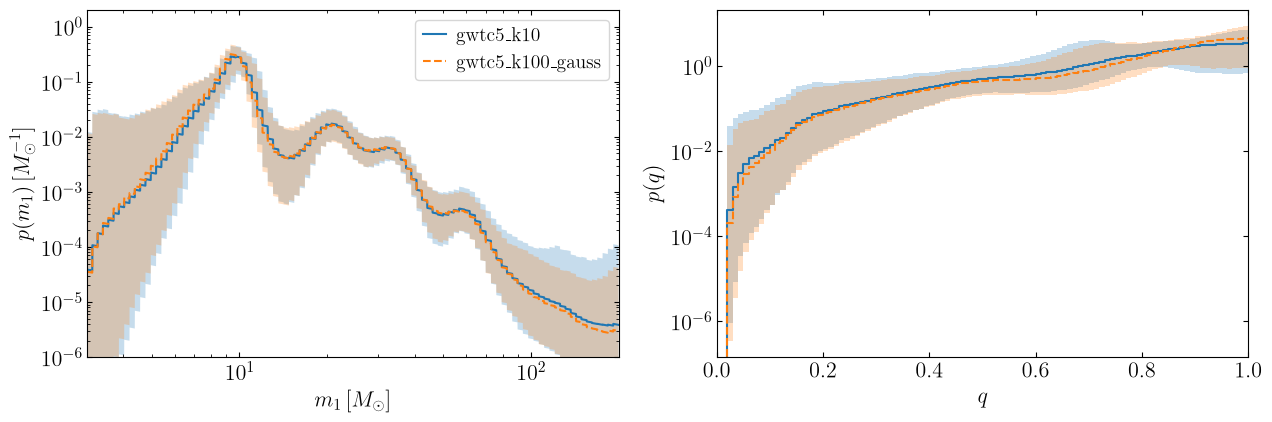

In [5]:
N_FINE = 50
m_edges = np.exp(A.lnm_edges)
m_fine = np.concatenate([np.linspace(a, b, N_FINE, endpoint=False) for a, b in zip(m_edges[:-1], m_edges[1:])])
idx_fine = np.repeat(np.arange(A.B), N_FINE)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for run in RUNS:
    r = R[run]
    lo, med, hi = band(r.p_lnm[:, idx_fine] / m_fine[None])
    axes[0].fill_between(m_fine, lo, hi, color=COL[run], alpha=0.25, lw=0)
    axes[0].plot(m_fine, med, color=COL[run], ls=LS[run], label=LAB[run])
    lo, med, hi = band(np.concatenate([r.p_q, r.p_q[:, -1:]], 1))
    axes[1].fill_between(A.q_edges, lo, hi, step='post', color=COL[run], alpha=0.25, lw=0)
    axes[1].step(A.q_edges, med, where='post', color=COL[run], ls=LS[run])
axes[0].set_xscale('log'); axes[0].set_yscale('log'); axes[0].set_xlim(A.MIN_M, A.MAX_M)
axes[0].set_ylim(1e-6, 2); axes[0].set_xlabel(r'$m_1\,[M_\odot]$'); axes[0].set_ylabel(r'$p(m_1)\,[M_\odot^{-1}]$')
axes[0].legend(**plot_style.LEG_KW)
axes[1].set_yscale('log'); axes[1].set_xlim(0, 1); axes[1].set_xlabel(r'$q$'); axes[1].set_ylabel(r'$p(q)$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_mass_marginals')

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_m1_given_q.pdf
share of the population in each q range, median [5%, 95%]


,ppc_gwtc5_k10,ppc_gwtc5_k100_gauss
0.1 < q < 0.4,"0.045 [0.013, 0.118]","0.041 [0.012, 0.095]"
0.4 < q < 0.6,"0.100 [0.051, 0.196]","0.084 [0.046, 0.156]"
0.6 < q < 0.8,"0.241 [0.100, 0.618]","0.185 [0.076, 0.549]"
0.8 < q < 1,"0.598 [0.183, 0.784]","0.679 [0.264, 0.819]"


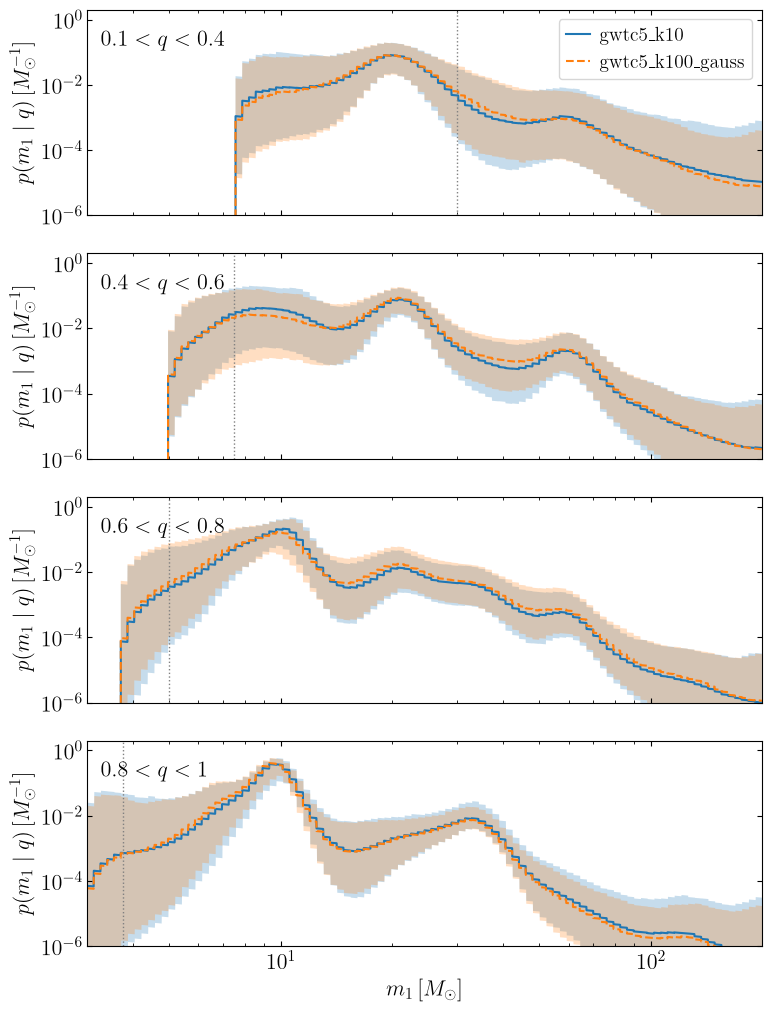

In [6]:
Q_RANGES = [(0.1, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
fig, axes = plt.subplots(len(Q_RANGES), 1, figsize=(8, 2.6 * len(Q_RANGES)), sharex=True)
rows = {}
for ax, (qlo, qhi) in zip(axes, Q_RANGES):
    sel = (A.q_edges[:-1] >= qlo - 1e-9) & (A.q_edges[1:] <= qhi + 1e-9)
    for run in RUNS:
        p = R[run].p_mass[:, :, sel].sum(2) * A.dq
        share = p.sum(1) * A.dlnm
        rows.setdefault(f'{qlo:g} < q < {qhi:g}', {})[run] = fmt(share)
        lo, med, hi = band((p / share[:, None])[:, idx_fine] / m_fine[None])
        ax.fill_between(m_fine, lo, hi, color=COL[run], alpha=0.25, lw=0)
        ax.plot(m_fine, med, color=COL[run], ls=LS[run], label=LAB[run])
    ax.axvline(A.MIN_M / qlo, color='0.5', ls=':', lw=1)
    ax.text(0.02, 0.9, rf'${qlo:g} < q < {qhi:g}$', transform=ax.transAxes, va='top')
    ax.set_yscale('log'); ax.set_ylim(1e-6, 2); ax.set_ylabel(r'$p(m_1 \mid q)\,[M_\odot^{-1}]$')
axes[0].legend(loc='upper right', **plot_style.LEG_KW)
axes[-1].set_xscale('log'); axes[-1].set_xlim(A.MIN_M, A.MAX_M); axes[-1].set_xlabel(r'$m_1\,[M_\odot]$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_m1_given_q')
print('share of the population in each q range, median [5%, 95%]')
pd.DataFrame(rows).T

### Masses in $\chi_\mathrm{eff}$ slices

$p(m_1 \mid \chi_\mathrm{eff} \in S)$ and $p(q \mid \chi_\mathrm{eff} \in S)$, from
$p(\ln m_1, q \mid S) \propto p(\ln m_1, q)\, P(\chi_\mathrm{eff} \in S \mid m_1, q)$ with the windowed mass
distribution and the spin conditional of each draw. The slices overlap: $0 < \chi_\mathrm{eff} < 0.1$ is inside
$|\chi_\mathrm{eff}| < 0.2$. The table gives each slice's share of the population, $P(\chi_\mathrm{eff} \in S)$.

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_mass_given_chieff.pdf
share of the population in each chi_eff slice, median [5%, 95%]


,ppc_gwtc5_k10,ppc_gwtc5_k100_gauss
0 < chi_eff < 0.1,"0.493 [0.387, 0.592]","0.508 [0.415, 0.613]"
|chi_eff| < 0.2,"0.918 [0.782, 0.959]","0.938 [0.893, 0.963]"
|chi_eff| > 0.2,"0.082 [0.041, 0.218]","0.062 [0.037, 0.107]"


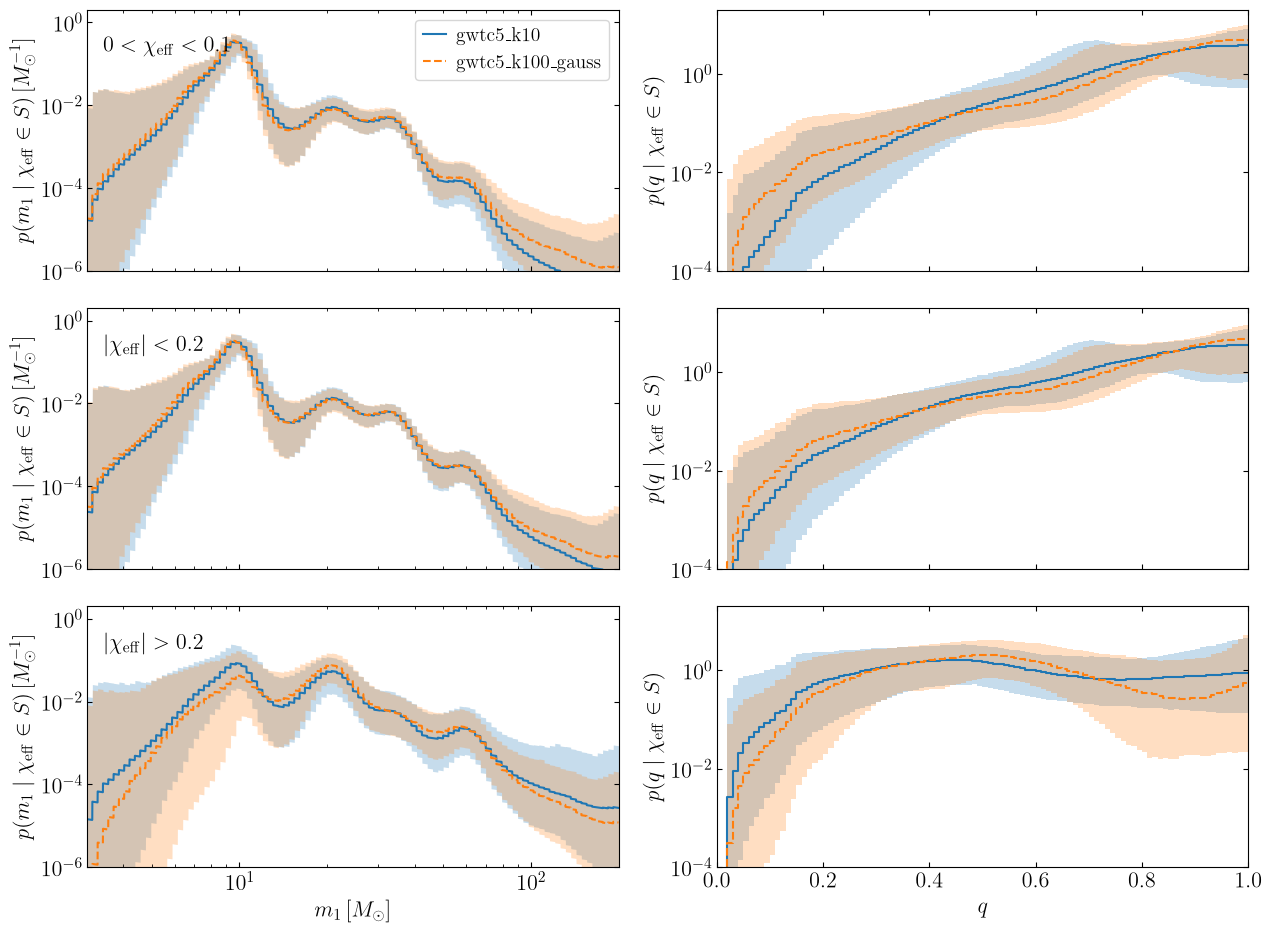

In [7]:
SL = list(A.CHI_EFF_SLICES)
fig, axes = plt.subplots(len(SL), 2, figsize=(13, 3.2 * len(SL)), sharex='col')
for j, lab in enumerate(SL):
    for run in RUNS:
        pms = R[run].p_mass_slice[..., j]                                      # (draws, ln m1, q)
        p_lnm = pms.sum(2) * A.dq; p_q = pms.sum(1) * A.dlnm
        lo, med, hi = band(p_lnm[:, idx_fine] / m_fine[None])
        axes[j, 0].fill_between(m_fine, lo, hi, color=COL[run], alpha=0.25, lw=0)
        axes[j, 0].plot(m_fine, med, color=COL[run], ls=LS[run], label=LAB[run])
        lo, med, hi = band(np.concatenate([p_q, p_q[:, -1:]], 1))
        axes[j, 1].fill_between(A.q_edges, lo, hi, step='post', color=COL[run], alpha=0.25, lw=0)
        axes[j, 1].step(A.q_edges, med, where='post', color=COL[run], ls=LS[run])
    axes[j, 0].text(0.03, 0.9, f'${lab}$', transform=axes[j, 0].transAxes, va='top')
    axes[j, 0].set_xscale('log'); axes[j, 0].set_yscale('log'); axes[j, 0].set_ylim(1e-6, 2)
    axes[j, 0].set_ylabel(r'$p(m_1 \mid \chi_\mathrm{eff} \in S)\,[M_\odot^{-1}]$')
    axes[j, 1].set_yscale('log'); axes[j, 1].set_ylim(1e-4, 20)
    axes[j, 1].set_ylabel(r'$p(q \mid \chi_\mathrm{eff} \in S)$')
axes[0, 0].legend(loc='upper right', **plot_style.LEG_KW)
axes[-1, 0].set_xlim(A.MIN_M, A.MAX_M); axes[-1, 0].set_xlabel(r'$m_1\,[M_\odot]$')
axes[-1, 1].set_xlim(0, 1); axes[-1, 1].set_xlabel(r'$q$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_mass_given_chieff')
print('share of the population in each chi_eff slice, median [5%, 95%]')
PLAIN = ['0 < chi_eff < 0.1', '|chi_eff| < 0.2', '|chi_eff| > 0.2']
pd.DataFrame({run: {PLAIN[j]: fmt(R[run].slice_share[:, j]) for j in range(len(SL))} for run in RUNS})

## Spins: the population marginal (windowed)

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_spin_marginal.pdf
population spin moments (windowed), median [5%, 95%]


,ppc_gwtc5_k10,ppc_gwtc5_k100_gauss
mean chi_eff,"0.032 [-0.082, 0.063]","0.032 [0.015, 0.050]"
sd chi_eff,"0.139 [0.099, 0.337]","0.109 [0.087, 0.148]"
P(chi_eff < 0),"0.309 [0.200, 0.446]","0.317 [0.220, 0.413]"
mean chi_p,"0.230 [0.179, 0.292]","0.274 [0.211, 0.341]"


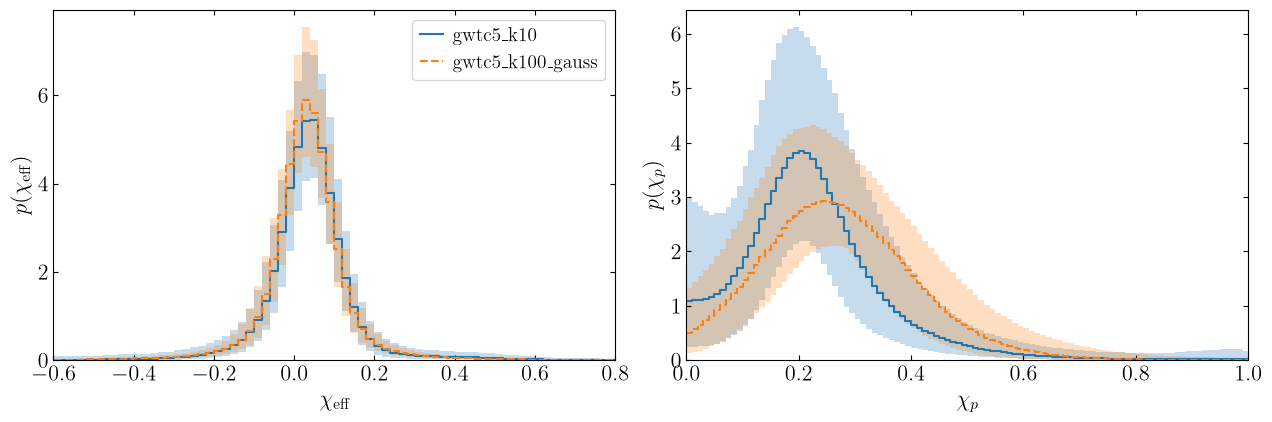

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for run in RUNS:
    for ax, y, edges in zip(axes, A.spin_1d(R[run].P_win), (A.e_edges, A.p_edges)):
        lo, med, hi = band(np.concatenate([y, y[:, -1:]], 1))
        ax.fill_between(edges, lo, hi, step='post', color=COL[run], alpha=0.25, lw=0)
        ax.step(edges, med, where='post', color=COL[run], ls=LS[run], label=LAB[run])
for ax, edges, lab in ((axes[0], A.e_edges, r'\chi_\mathrm{eff}'), (axes[1], A.p_edges, r'\chi_p')):
    ax.set_xlim(edges[0], edges[-1]); ax.set_ylim(0); ax.set_xlabel(rf'${lab}$'); ax.set_ylabel(rf'$p({lab})$')
axes[0].set_xlim(-0.6, 0.8); axes[0].legend(**plot_style.LEG_KW)
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_spin_marginal')
tabs = {run: A.spin_moments_table(R[run].P_win).apply(fmt) for run in RUNS}
print('population spin moments (windowed), median [5%, 95%]')
pd.DataFrame(tabs)

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_spin_joint.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_spin_joint.pdf'

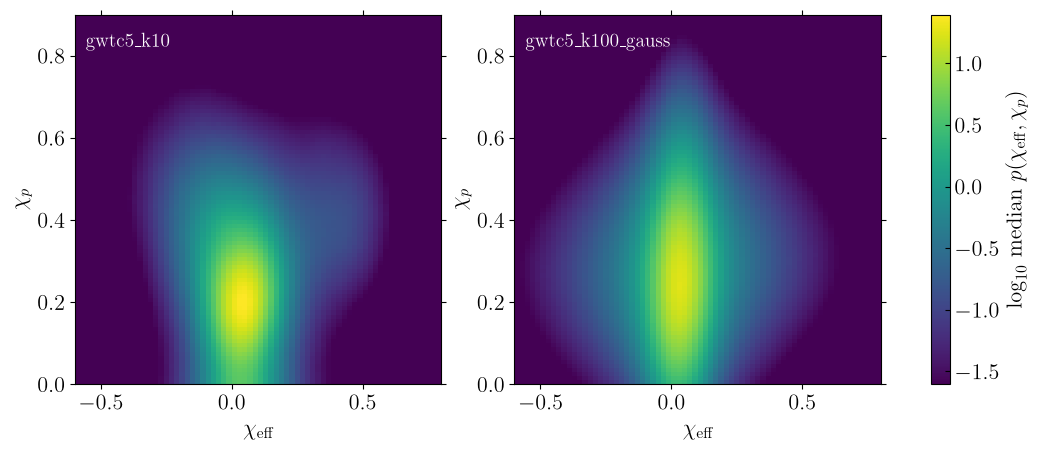

In [9]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(6.5 * len(RUNS), 4.8), squeeze=False)
meds = {run: np.median(R[run].P_win, 0) / (A.de * A.dp) for run in RUNS}
vmax = np.log10(max(m.max() for m in meds.values())); vmin = vmax - 3
for ax, run in zip(axes[0], RUNS):
    pc = ax.pcolormesh(A.e_edges, A.p_edges, np.log10(np.maximum(meds[run], 1e-300)).T, vmin=vmin, vmax=vmax,
                       cmap='viridis', shading='flat', rasterized=True)
    ax.tick_params(which='both', direction='out')
    ax.set_xlabel(r'$\chi_\mathrm{eff}$'); ax.set_ylabel(r'$\chi_p$'); ax.set_xlim(-0.6, 0.8); ax.set_ylim(0, 0.9)
    ax.text(0.03, 0.95, LAB[run], transform=ax.transAxes, va='top', color='w', fontsize=14)
cb = fig.colorbar(pc, ax=axes[0].tolist()); cb.set_label(r'$\log_{10}$ median $p(\chi_\mathrm{eff}, \chi_p)$')
plot_style.save(fig, f'compare_{NAME}_spin_joint')

## Spin moments as a function of primary mass

The conditional's mean and sd of $\chi_\mathrm{eff}$ and $\chi_p$ in every $m_1$ bin, first at $q \approx 1$ (the top
$q$ bin), then in $q$ slices (one row per slice). Bins with $q\,m_1 < 3\,M_\odot$ are dropped. With no data, the field
relaxes towards a flat density on the physical region: mean $\chi_\mathrm{eff} = 0$, sd $\chi_\mathrm{eff} \approx 0.52$,
mean $\chi_p \approx 0.46$, sd $\chi_p \approx 0.28$.

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_spin_moments_q1.pdf
q ~ 1: median [5%, 95%] over draws


ppc_gwtc5_k10   ppc_gwtc5_k100_gauss
10 Msun mean chi_eff  0.041 [-0.007, 0.075]  0.046 [-0.006, 0.103]
        sd chi_eff     0.072 [0.048, 0.211]   0.051 [0.025, 0.098]
        mean chi_p     0.212 [0.148, 0.289]   0.263 [0.160, 0.388]
        sd chi_p       0.086 [0.052, 0.149]   0.114 [0.056, 0.202]
20 Msun mean chi_eff  0.032 [-0.014, 0.068]  0.030 [-0.036, 0.092]
        sd chi_eff     0.079 [0.054, 0.178]   0.057 [0.027, 0.157]
        mean chi_p     0.250 [0.179, 0.335]   0.289 [0.176, 0.436]
        sd chi_p       0.097 [0.060, 0.151]   0.120 [0.058, 0.210]
35 Msun mean chi_eff  0.014 [-0.052, 0.048]  0.018 [-0.037, 0.064]
        sd chi_eff     0.107 [0.072, 0.242]   0.069 [0.035, 0.124]
        mean chi_p     0.291 [0.218, 0.377]   0.304 [0.216, 0.418]
        sd chi_p       0.121 [0.078, 0.178]   0.128 [0.070, 0.219]
60 Msun mean chi_eff  0.031 [-0.355, 0.222]  0.025 [-0.047, 0.091]
        sd chi_eff     0.186 [0.092, 0.412]   0.112 [0.036, 0.391]
        mean chi_p     0.376 [0.192, 0.578]   0.338 [0.209, 0.529]
        sd chi_p       0.160 [0.087, 0.272]   0.130 [0.059, 0.248]

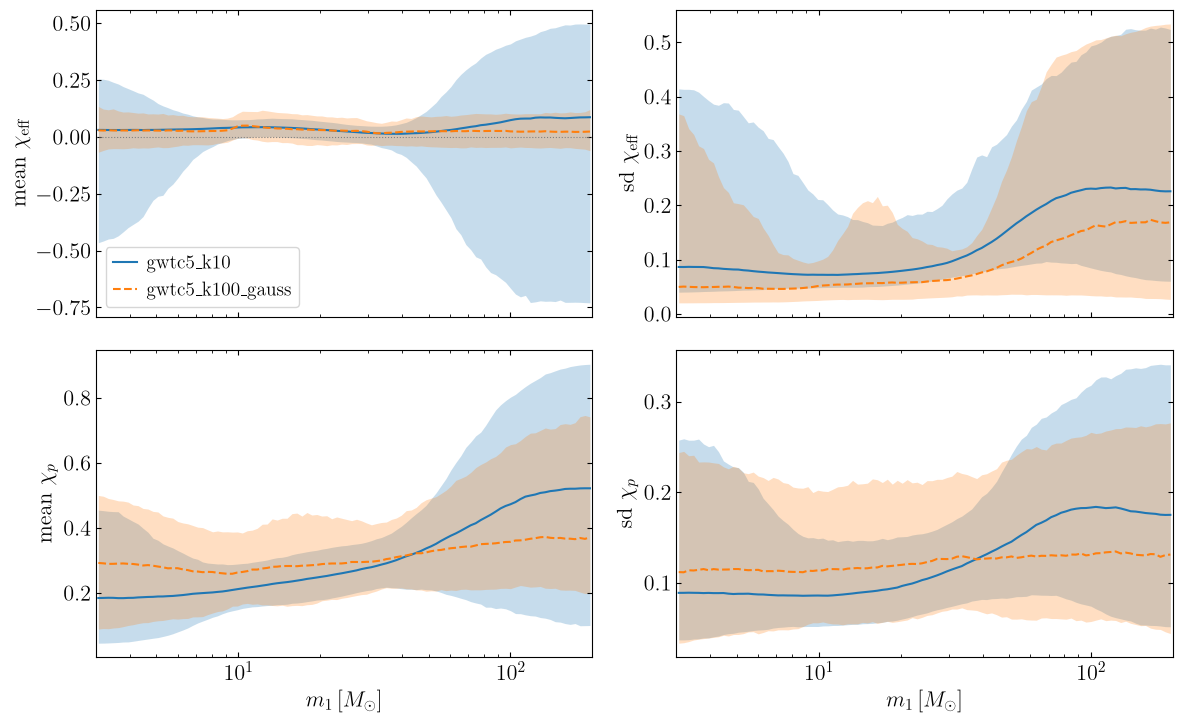

In [10]:
MOM_LABELS = [r'mean $\chi_\mathrm{eff}$', r'sd $\chi_\mathrm{eff}$', r'mean $\chi_p$', r'sd $\chi_p$']

def moment_panels(axes, run, iq, label=None):
    ok = A.q_c[iq] * A.m_c >= A.MIN_M
    for k, ax in enumerate(axes):
        lo, med, hi = band(R[run].MOM[:, ok, iq, k])
        ax.fill_between(A.m_c[ok], lo, hi, color=COL[run], alpha=0.25, lw=0)
        ax.plot(A.m_c[ok], med, color=COL[run], ls=LS[run], label=label)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for run in RUNS:
    moment_panels(axes.ravel(), run, -1, label=LAB[run])
for ax, lab in zip(axes.ravel(), MOM_LABELS):
    ax.set_ylabel(lab); ax.set_xscale('log'); ax.set_xlim(A.MIN_M, A.MAX_M)
axes[0, 0].axhline(0, color='0.5', lw=0.8, ls=':'); axes[0, 0].legend(**plot_style.LEG_KW)
for ax in axes[1]:
    ax.set_xlabel(r'$m_1\,[M_\odot]$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_spin_moments_q1')

rows = {}
for m in (10., 20., 35., 60.):
    im = int(np.argmin(np.abs(A.m_c - m)))
    for k, nm in enumerate(A.MOM_NAMES):
        rows[(f'{A.m_c[im]:.0f} Msun', nm)] = {run: fmt(R[run].MOM[:, im, -1, k]) for run in RUNS}
print('q ~ 1: median [5%, 95%] over draws')
pd.DataFrame(rows).T

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_spin_moments_q_slices.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_spin_moments_q_slices.pdf'

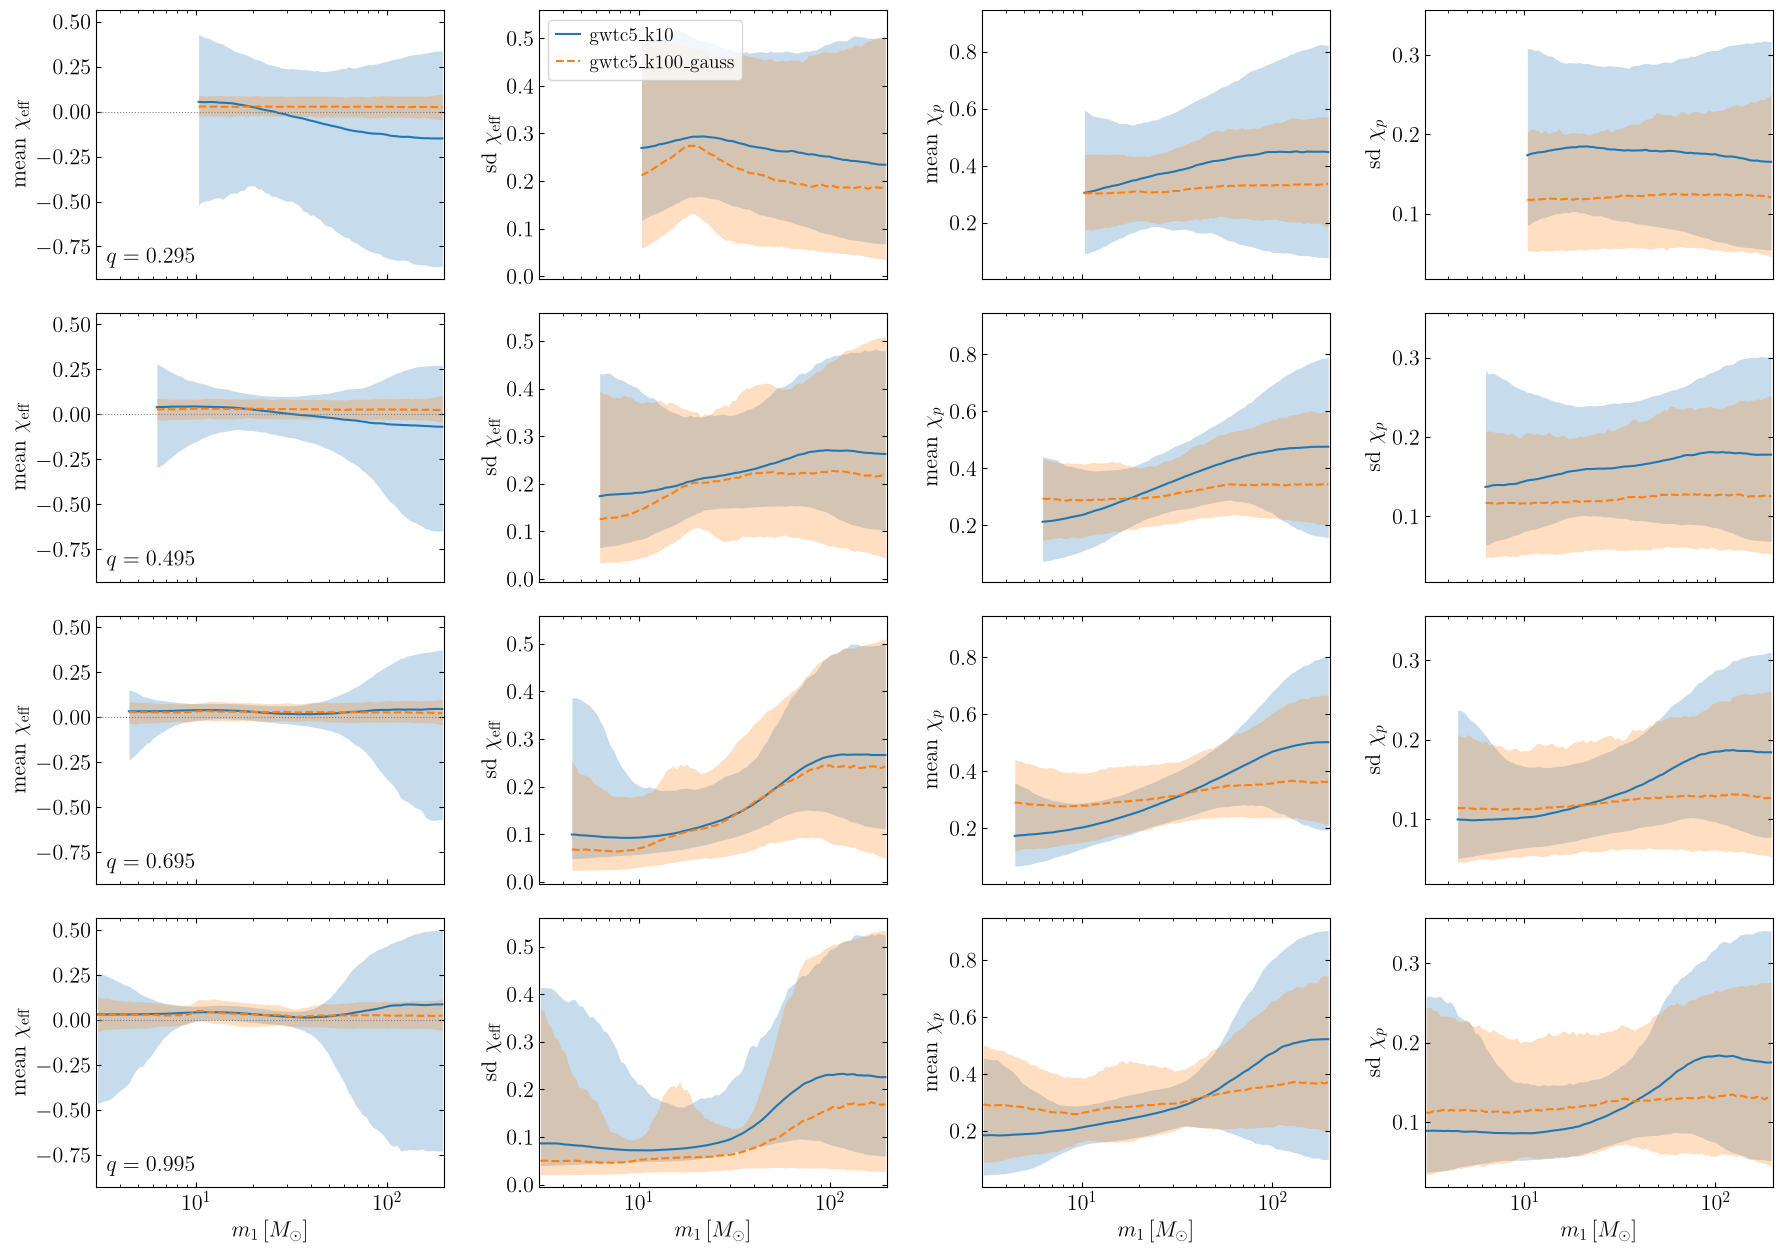

In [11]:
Q_SLICES = (0.3, 0.5, 0.7, 1.0)
fig, axes = plt.subplots(len(Q_SLICES), 4, figsize=(18, 3.2 * len(Q_SLICES)), sharex=True, sharey='col')
for rr, qv in enumerate(Q_SLICES):
    iq = int(np.argmin(np.abs(A.q_c - qv)))
    for run in RUNS:
        moment_panels(axes[rr], run, iq, label=LAB[run])
    axes[rr, 0].text(0.03, 0.06, rf'$q = {A.q_c[iq]:.3f}$', transform=axes[rr, 0].transAxes)
    axes[rr, 0].axhline(0, color='0.5', lw=0.8, ls=':')
for c, lab in enumerate(MOM_LABELS):
    axes[-1, c].set_xlabel(r'$m_1\,[M_\odot]$')
    for rr in range(len(Q_SLICES)):
        axes[rr, c].set_ylabel(lab)
axes[0, 0].set_xscale('log'); axes[0, 0].set_xlim(A.MIN_M, A.MAX_M)
axes[0, 1].legend(loc='upper left', **plot_style.LEG_KW)
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_spin_moments_q_slices')

## Spin moments given primary mass alone

The moments above are of the conditional at fixed $(m_1, q)$. At a given $m_1$ the population mixes mass ratios with the
windowed $p(q \mid m_1)$, so $\mathrm{sd}^2(\chi \mid m_1) = \text{within}^2 + \text{between}^2$: the mean width at
fixed $q$, $\mathrm{E}_q[\mathrm{sd}^2(\chi \mid m_1, q)]$, plus the spread of the per-$q$ means,
$\mathrm{Var}_q[\mathrm{E}(\chi \mid m_1, q)]$ (`analysis.q_averaged_moments`).

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_spin_moments_given_m1.pdf
sd chi_eff given m1, and its within-q and between-q parts: median [5%, 95%] over draws


ppc_gwtc5_k10  ppc_gwtc5_k100_gauss
8.0   sd       0.099 [0.061, 0.296]  0.067 [0.038, 0.127]
      within   0.096 [0.060, 0.268]  0.063 [0.033, 0.124]
      between  0.017 [0.004, 0.124]  0.016 [0.004, 0.040]
12.2  sd       0.123 [0.074, 0.308]  0.108 [0.061, 0.223]
      within   0.117 [0.072, 0.262]  0.105 [0.057, 0.222]
      between  0.026 [0.006, 0.155]  0.018 [0.005, 0.046]
15.1  sd       0.199 [0.108, 0.417]  0.182 [0.097, 0.330]
      within   0.188 [0.103, 0.352]  0.180 [0.094, 0.328]
      between  0.050 [0.012, 0.231]  0.020 [0.007, 0.045]
17.9  sd       0.224 [0.139, 0.429]  0.208 [0.133, 0.338]
      within   0.213 [0.132, 0.367]  0.207 [0.130, 0.336]
      between  0.052 [0.012, 0.233]  0.020 [0.007, 0.044]
20.3  sd       0.220 [0.149, 0.414]  0.207 [0.147, 0.307]
      within   0.210 [0.143, 0.345]  0.205 [0.145, 0.306]
      between  0.049 [0.013, 0.215]  0.020 [0.006, 0.044]
25.0  sd       0.194 [0.129, 0.381]  0.170 [0.112, 0.257]
      within   0.184 [0.125, 0.315]  0.167 [0.109, 0.256]
      between  0.045 [0.013, 0.213]  0.020 [0.007, 0.044]
29.6  sd       0.140 [0.099, 0.323]  0.119 [0.080, 0.185]
      within   0.134 [0.096, 0.260]  0.116 [0.078, 0.183]
      between  0.030 [0.008, 0.165]  0.018 [0.005, 0.041]
35.0  sd       0.134 [0.097, 0.303]  0.109 [0.077, 0.156]
      within   0.129 [0.094, 0.247]  0.107 [0.074, 0.156]
      between  0.022 [0.006, 0.130]  0.017 [0.005, 0.039]
45.0  sd       0.203 [0.140, 0.429]  0.188 [0.122, 0.287]
      within   0.190 [0.134, 0.340]  0.186 [0.120, 0.286]
      between  0.051 [0.013, 0.252]  0.020 [0.006, 0.044]
60.4  sd       0.262 [0.180, 0.447]  0.236 [0.159, 0.332]
      within   0.245 [0.168, 0.369]  0.235 [0.156, 0.331]
      between  0.066 [0.017, 0.277]  0.018 [0.006, 0.044]
81.1  sd       0.296 [0.181, 0.493]  0.242 [0.139, 0.383]
      within   0.264 [0.156, 0.416]  0.240 [0.136, 0.382]
      between  0.101 [0.025, 0.348]  0.020 [0.007, 0.044]
100.0 sd       0.310 [0.173, 0.520]  0.244 [0.120, 0.415]
      within   0.269 [0.144, 0.437]  0.242 [0.119, 0.415]
      between  0.117 [0.027, 0.374]  0.021 [0.007, 0.047]

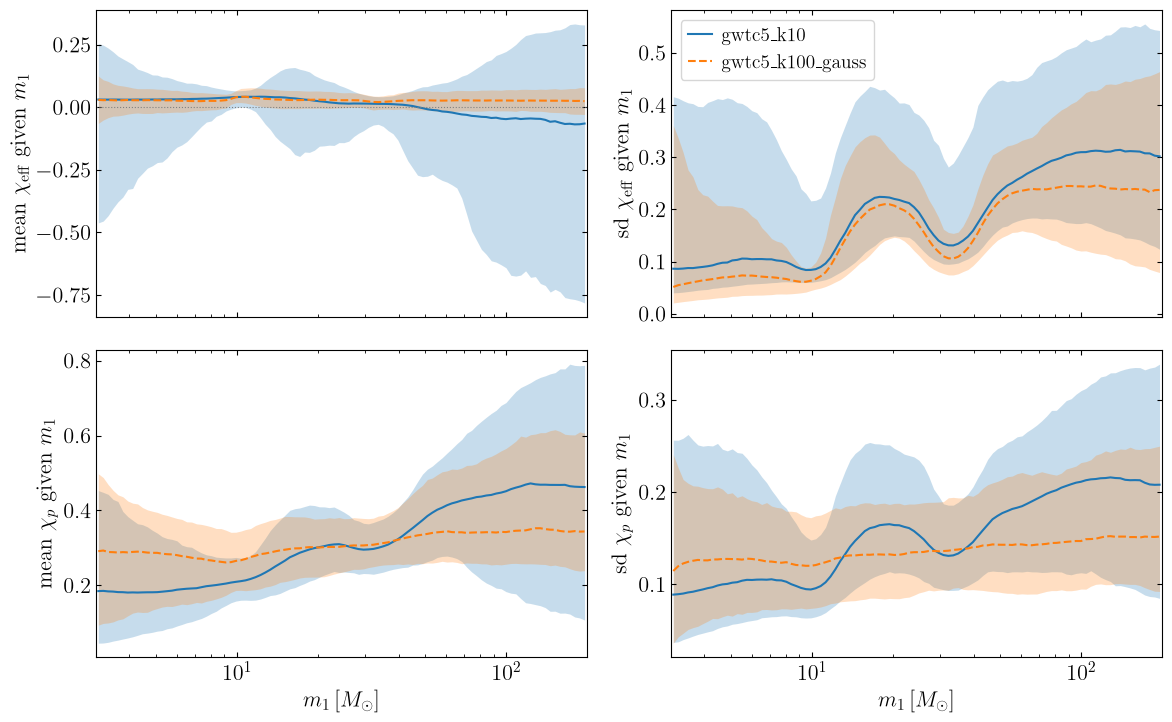

In [12]:
Q = {run: A.q_averaged_moments(R[run]) for run in RUNS}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for row, (name, lab) in enumerate((('chi_eff', r'\chi_\mathrm{eff}'), ('chi_p', r'\chi_p'))):
    for ax, key in zip(axes[row], ('mean', 'sd')):
        for run in RUNS:
            lo, med, hi = band(Q[run][name][key])
            ax.fill_between(A.m_c, lo, hi, color=COL[run], alpha=0.25, lw=0)
            ax.plot(A.m_c, med, color=COL[run], ls=LS[run], label=LAB[run])
        ax.set_ylabel(rf'{key} ${lab}$ given $m_1$')
axes[0, 0].axhline(0, color='0.5', lw=0.8, ls=':'); axes[0, 1].legend(**plot_style.LEG_KW)
for ax in axes.ravel():
    ax.set_xscale('log'); ax.set_xlim(A.MIN_M, A.MAX_M)
for ax in axes[1]:
    ax.set_xlabel(r'$m_1\,[M_\odot]$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_spin_moments_given_m1')

rows = {}
for m in (8., 12., 15., 18., 20., 25., 30., 35., 45., 60., 80., 100.):
    im = int(np.argmin(np.abs(A.m_c - m)))
    for key in ('sd', 'within', 'between'):
        rows[(f'{A.m_c[im]:.1f}', key)] = {run: fmt(Q[run]['chi_eff'][key][:, im]) for run in RUNS}
print('sd chi_eff given m1, and its within-q and between-q parts: median [5%, 95%] over draws')
pd.DataFrame(rows).T

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_chieff_width_split.pdf
sd chi_eff given m1 minus its value at 32 Msun (the 35 Msun peak), per draw


ppc_gwtc5_k10                                 \
                                      sd                         within   
                              difference P(> 0)              difference   
10 minus 32 Msun  -0.044 [-0.172, 0.053]   0.13  -0.040 [-0.140, 0.050]   
19 minus 32 Msun   0.083 [-0.028, 0.256]   0.91   0.079 [-0.018, 0.219]   
45 minus 32 Msun   0.067 [-0.003, 0.196]   0.94   0.061 [-0.002, 0.158]   
60 minus 32 Msun    0.122 [0.011, 0.267]   0.96    0.114 [0.014, 0.218]   
81 minus 32 Msun    0.152 [0.016, 0.346]   0.96    0.131 [0.006, 0.278]   

                                                        \
                                        between          
                 P(> 0)              difference P(> 0)   
10 minus 32 Msun   0.12  -0.010 [-0.109, 0.033]   0.25   
19 minus 32 Msun   0.93   0.023 [-0.049, 0.149]   0.78   
45 minus 32 Msun   0.95   0.023 [-0.022, 0.151]   0.83   
60 minus 32 Msun   0.96   0.036 [-0.029, 0.185]   0.86   
81 minus 32 Msun   0.96   0.067 [-0.018, 0.282]   0.91   

                     ppc_gwtc5_k100_gauss                                  \
                                       sd                          within   
                               difference P(> 0)               difference   
10 minus 32 Msun  -0.043 [-0.094, -0.003]   0.04  -0.044 [-0.096, -0.003]   
19 minus 32 Msun     0.101 [0.023, 0.220]   0.98     0.101 [0.023, 0.221]   
45 minus 32 Msun     0.078 [0.008, 0.177]   0.96     0.079 [0.008, 0.179]   
60 minus 32 Msun     0.126 [0.042, 0.227]   0.99     0.127 [0.042, 0.228]   
81 minus 32 Msun     0.133 [0.025, 0.274]   0.98     0.134 [0.024, 0.275]   

                                                        
                                        between         
                 P(> 0)              difference P(> 0)  
10 minus 32 Msun   0.04  -0.002 [-0.016, 0.013]   0.40  
19 minus 32 Msun   0.98   0.002 [-0.011, 0.019]   0.63  
45 minus 32 Msun   0.96   0.002 [-0.010, 0.020]   0.64  
60 minus 32 Msun   0.99   0.001 [-0.013, 0.018]   0.58  
81 minus 32 Msun   0.98   0.002 [-0.012, 0.020]   0.63

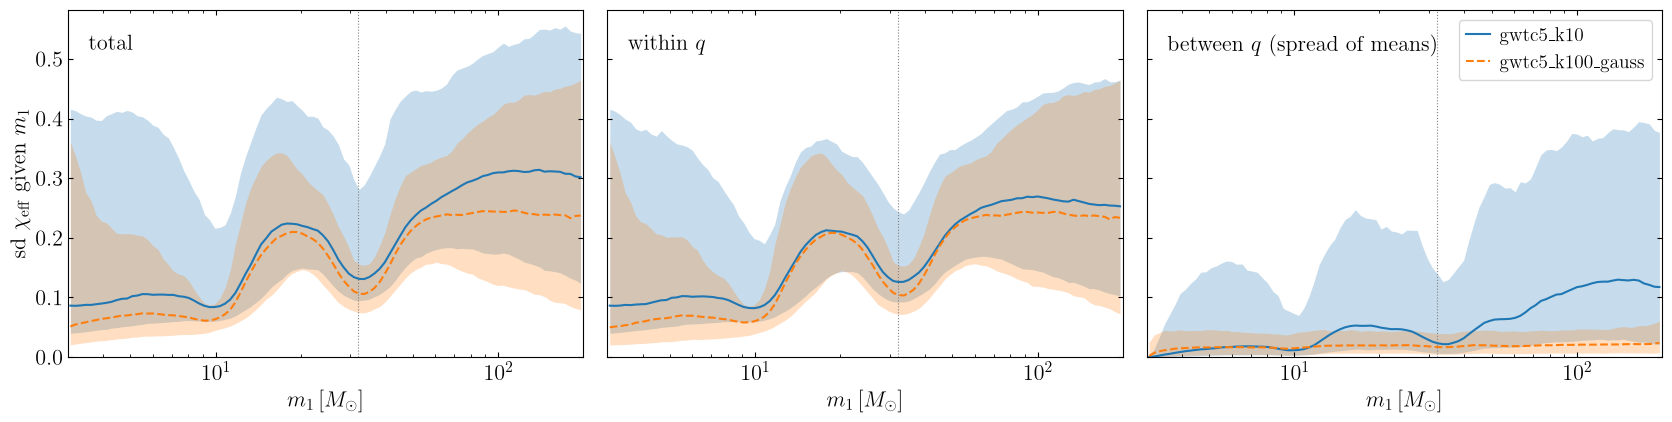

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, key, lab in zip(axes, ('sd', 'within', 'between'), ('total', r'within $q$', r'between $q$ (spread of means)')):
    for run in RUNS:
        lo, med, hi = band(Q[run]['chi_eff'][key])
        ax.fill_between(A.m_c, lo, hi, color=COL[run], alpha=0.25, lw=0)
        ax.plot(A.m_c, med, color=COL[run], ls=LS[run], label=LAB[run])
    ax.axvline(A.WIDTH_REF, color='0.5', lw=0.8, ls=':')
    ax.text(0.04, 0.93, lab, transform=ax.transAxes, va='top')
    ax.set_xscale('log'); ax.set_xlim(A.MIN_M, A.MAX_M); ax.set_ylim(0); ax.set_xlabel(r'$m_1\,[M_\odot]$')
axes[0].set_ylabel(r'sd $\chi_\mathrm{eff}$ given $m_1$'); axes[-1].legend(loc='upper right', **plot_style.LEG_KW)
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_chieff_width_split')
print(f'sd chi_eff given m1 minus its value at {A.WIDTH_REF:g} Msun (the 35 Msun peak), per draw')
pd.concat({(run, k): A.width_contrasts(Q[run], key=k) for run in RUNS for k in ('sd', 'within', 'between')}, axis=1)

## Mass ratio and spin width, side by side

One column per run, with shared $y$ ranges and colour scales (`analysis.summary_figure`): (1) the windowed $p(m_1)$;
(2) the median $p(q \mid m_1)$ with the mean $q$ given $m_1$; (3) the median $\chi_\mathrm{eff}$ width at fixed
$(m_1, q)$ with the 25–75% (solid) and 5–95% (dashed) quantiles of $p(q \mid m_1)$; (4) sd($\chi_\mathrm{eff} \mid m_1$)
and its within-$q$ and between-$q$ parts. Dotted lines: each run's $p(m_1)$ peaks; dashed: twice those masses. Read
panel 3 between the quantile lines: outside them there are few events and the width follows the prior.

ppc_gwtc5_k10: p(m1) peaks 9.5, 25.0 Msun
ppc_gwtc5_k100_gauss: p(m1) peaks 9.5, 25.0 Msun


Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_mass_ratio_spin_summary.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_mass_ratio_spin_summary.pdf'

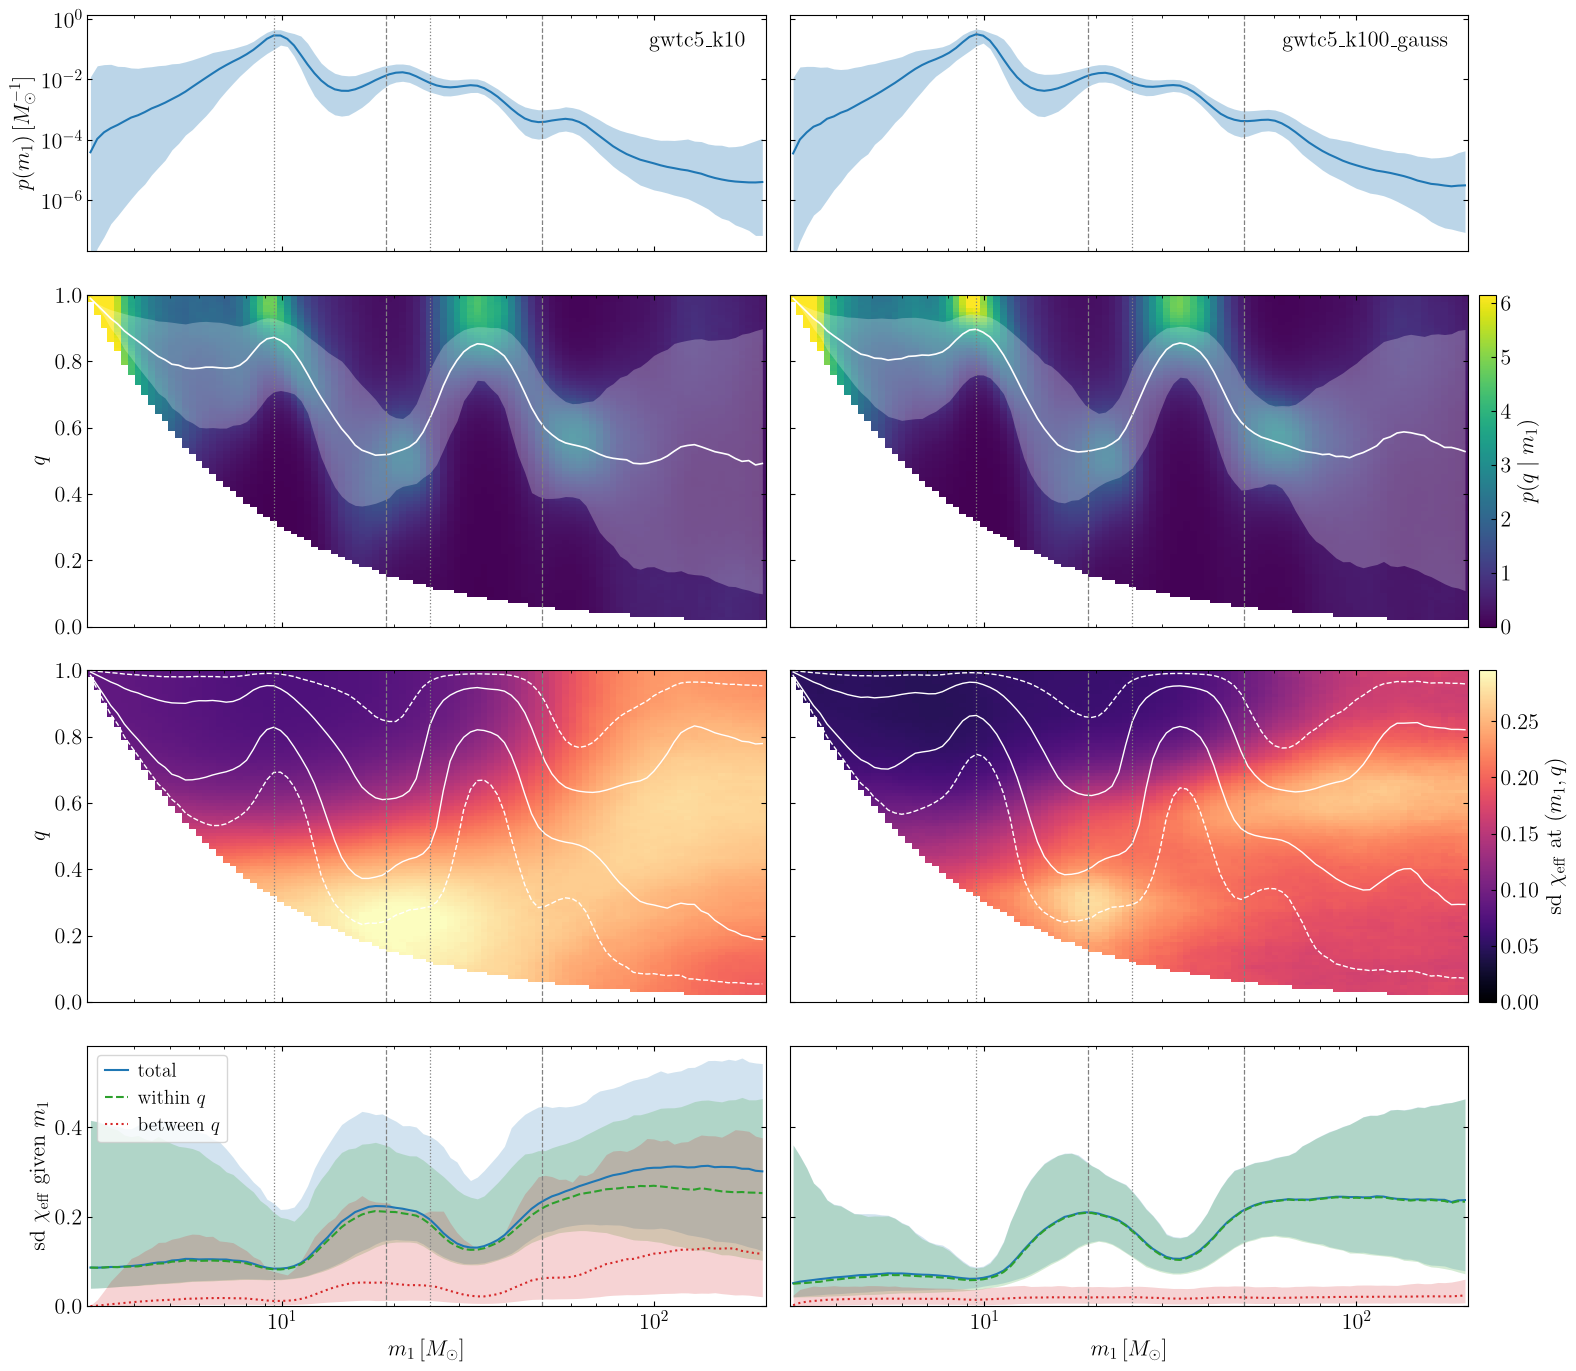

In [14]:
fig, peaks = A.summary_figure([R[run] for run in RUNS], [LAB[run] for run in RUNS])
for run, pk in zip(RUNS, peaks):
    print(f'{run}: p(m1) peaks ' + ', '.join(f'{m:.1f}' for m in pk) + ' Msun')
plot_style.save(fig, f'compare_{NAME}_mass_ratio_spin_summary')

## Spin distributions at fixed primary mass

$p(\chi_\mathrm{eff} \mid m_1)$ and $p(\chi_p \mid m_1)$ in the $m_1$ bin nearest each mass, averaged over $q$ with
the windowed $p(q \mid m_1)$ (so the low-$q$ corner excluded by $m_2 > 3\,M_\odot$ does not contribute). Log $y$ axes,
so the tails show.

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_chieff_given_m1.pdf


Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_gauss_k100_chip_given_m1.pdf


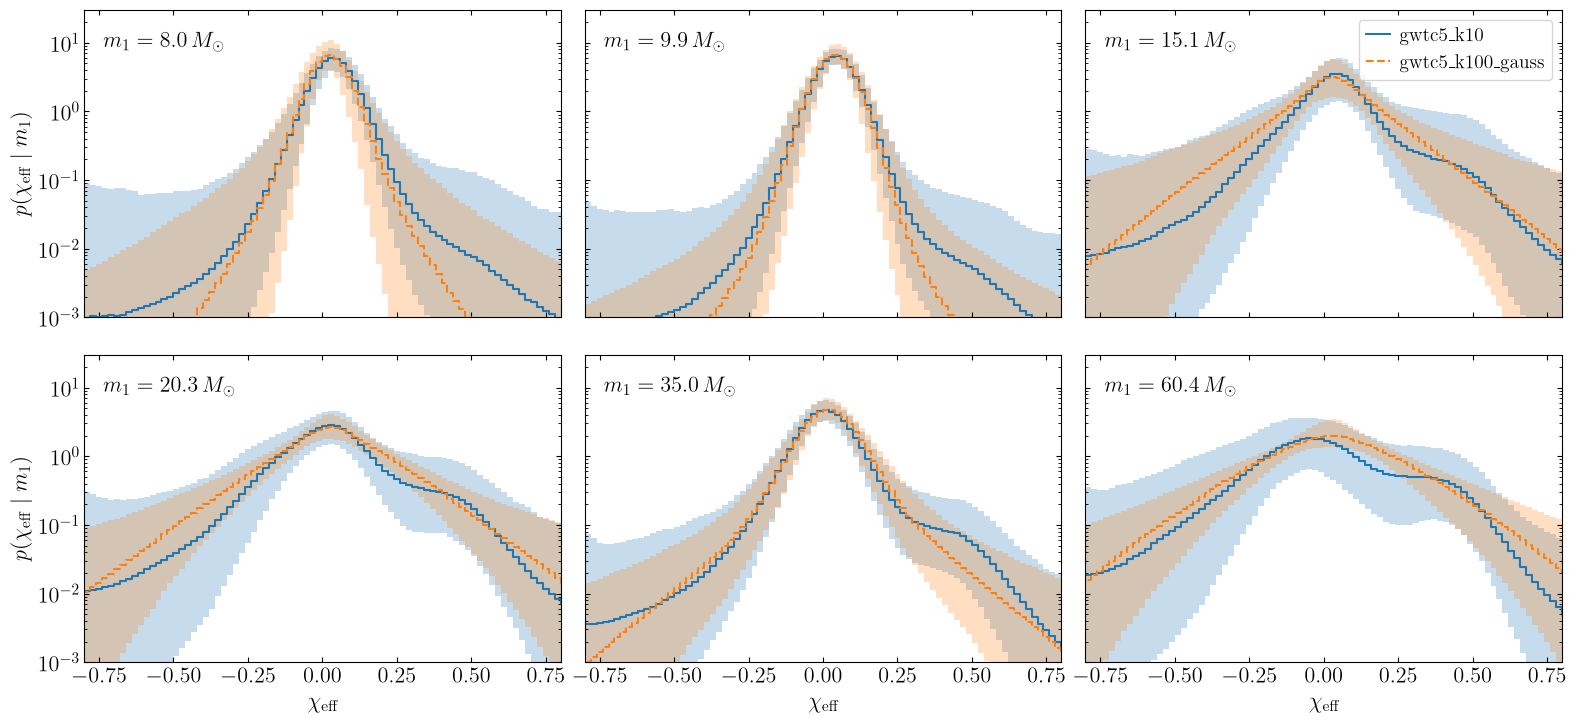

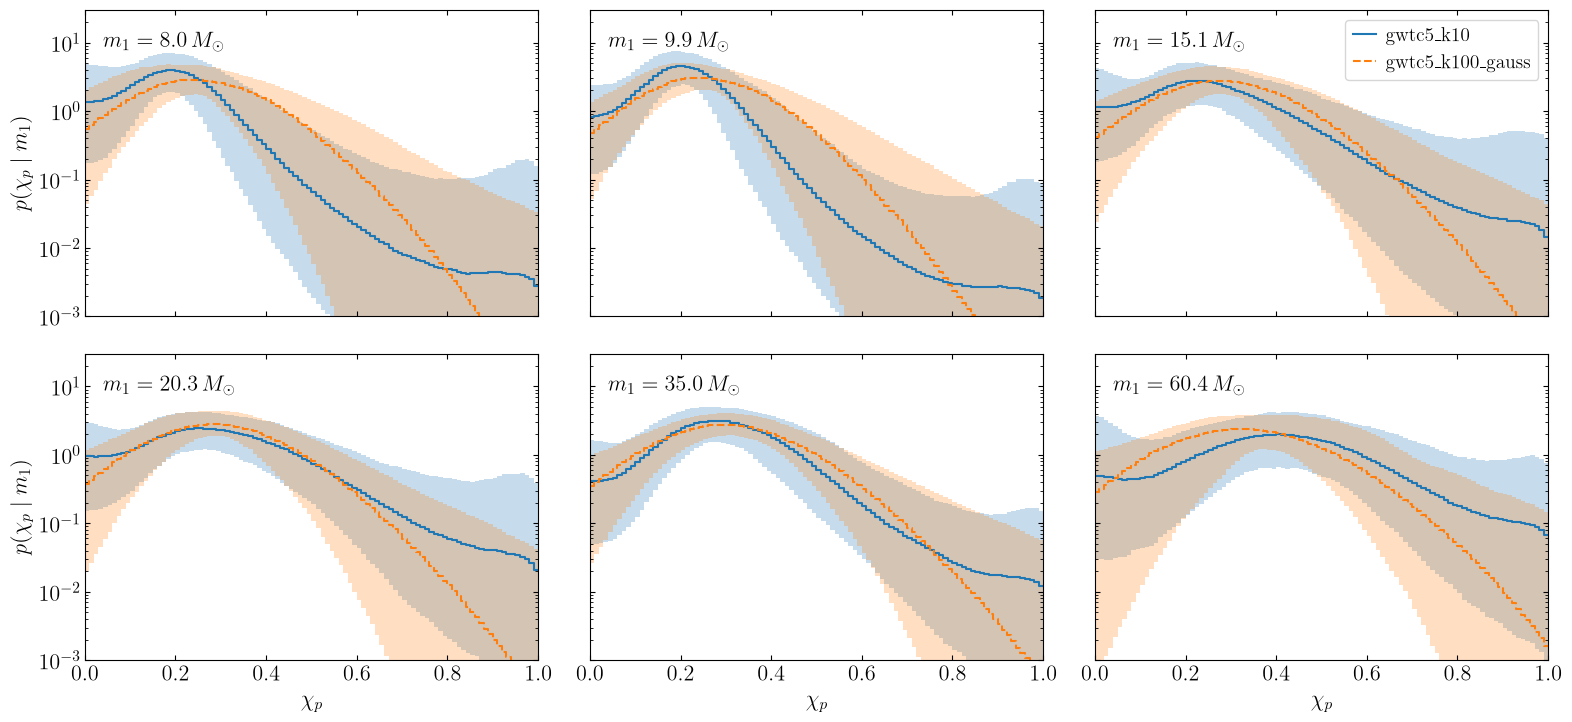

In [15]:
M_SEL = (8., 10., 15., 20., 35., 60.)
for key, edges, d, lab, xlim, nm in (('PE_M', A.e_edges, A.de, r'\chi_\mathrm{eff}', (-0.8, 0.8), 'chieff'),
                                     ('PP_M', A.p_edges, A.dp, r'\chi_p', (0., 1.), 'chip')):
    fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True, sharey=True)
    for ax, m in zip(axes.ravel(), M_SEL):
        im = int(np.argmin(np.abs(A.m_c - m)))
        for run in RUNS:
            y = getattr(R[run], key)[:, im] / d
            lo, med, hi = band(np.concatenate([y, y[:, -1:]], 1))
            ax.fill_between(edges, np.maximum(lo, 1e-12), hi, step='post', color=COL[run], alpha=0.25, lw=0)
            ax.step(edges, med, where='post', color=COL[run], ls=LS[run], label=LAB[run])
        ax.text(0.04, 0.93, rf'$m_1 = {A.m_c[im]:.1f}\,M_\odot$', transform=ax.transAxes, va='top')
        ax.set_yscale('log'); ax.set_ylim(1e-3, 30); ax.set_xlim(*xlim)
    for ax in axes[-1]:
        ax.set_xlabel(rf'${lab}$')
    for ax in axes[:, 0]:
        ax.set_ylabel(rf'$p({lab} \mid m_1)$')
    axes[0, -1].legend(loc='upper right', **plot_style.LEG_KW)
    fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_{nm}_given_m1')

In [16]:
# how much does the spin distribution change between 10 and 60 Msun (q ~ 1), per run?
i10, i60 = (int(np.argmin(np.abs(A.m_c - m))) for m in (10., 60.))
rows = {}
for k, nm in enumerate(A.MOM_NAMES):
    for run in RUNS:
        d = R[run].MOM[:, i60, -1, k] - R[run].MOM[:, i10, -1, k]
        rows.setdefault(f'{nm}: 60 minus 10 Msun', {})[run] = fmt(d) + f'; P(> 0) {np.mean(d > 0):.2f}'
pd.DataFrame(rows).T

,ppc_gwtc5_k10,ppc_gwtc5_k100_gauss
mean chi_eff: 60 minus 10 Msun,"-0.007 [-0.410, 0.227]; P(> 0) 0.47","-0.020 [-0.117, 0.054]; P(> 0) 0.32"
sd chi_eff: 60 minus 10 Msun,"0.106 [-0.044, 0.308]; P(> 0) 0.92","0.060 [-0.033, 0.333]; P(> 0) 0.83"
mean chi_p: 60 minus 10 Msun,"0.158 [-0.045, 0.372]; P(> 0) 0.92","0.067 [-0.088, 0.298]; P(> 0) 0.76"
sd chi_p: 60 minus 10 Msun,"0.070 [-0.018, 0.184]; P(> 0) 0.92","0.013 [-0.074, 0.135]; P(> 0) 0.62"
